# Predicting below-average US nursing homes

MLDA CW1, 00017694. CMS Care Compare, Oct 2026.

## A. Data load

4 files, joined on CCN.

In [1]:
import pandas as pd
import numpy as np

### A.1 Loading the files

I read CCN as string, otherwise 015009 becomes 15009.

In [2]:
# key column, same in all 4 files
CCN = 'CMS Certification Number (CCN)'

provider = pd.read_csv('../data/raw/NH_ProviderInfo_Oct2026.csv', dtype={CCN: str})
citations = pd.read_csv('../data/raw/NH_HealthCitations_Oct2026.csv', dtype={CCN: str})
penalties = pd.read_csv('../data/raw/NH_Penalties_Oct2026.csv', dtype={CCN: str})
ownership = pd.read_csv('../data/raw/NH_Ownership_Oct2026.csv', dtype={CCN: str})

print(provider.shape, citations.shape, penalties.shape, ownership.shape)

(14686, 102) (418682, 24) (15007, 14) (252468, 13)


In [3]:
provider.head()

,CMS Certification Number (CCN),Provider Name,Provider Address,City/Town,State,ZIP Code,Telephone Number,Provider SSA County Code,County/Parish,Urban,...,Number of Citations from Infection Control Inspections,Number of Fines,Total Amount of Fines in Dollars,Number of Payment Denials,Total Number of Penalties,Location,Latitude,Longitude,Geocoding Footnote,Processing Date
0,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,2563324110,290,Franklin,N,...,NaN,0,0.0,0,0,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",34.5149,-87.736,NaN,2026-10-01
1,015010,COOSA VALLEY HEALTHCARE CENTER,260 WEST WALNUT STREET,SYLACAUGA,AL,35150,2562495604,600,Talladega,N,...,NaN,0,0.0,0,0,"260 WEST WALNUT STREET,SYLACAUGA,AL,35150",33.1637,-86.254,NaN,2026-10-01
2,015012,HIGHLANDS HEALTH AND REHAB,380 WOODS COVE ROAD,SCOTTSBORO,AL,35768,2562183708,350,Jackson,N,...,NaN,0,0.0,0,0,"380 WOODS COVE ROAD,SCOTTSBORO,AL,35768",34.6611,-86.047,NaN,2026-10-01
3,015014,THE HEALTHCARE CENTER OF EASTVIEW,7755 FOURTH AVENUE SOUTH,BIRMINGHAM,AL,35206,2058330146,360,Jefferson,Y,...,NaN,0,0.0,0,0,"7755 FOURTH AVENUE SOUTH,BIRMINGHAM,AL,35206",33.5595,-86.722,NaN,2026-10-01
4,015015,PLANTATION MANOR NURSING HOME,6450 OLD TUSCALOOSA HIGHWAY,MC CALLA,AL,35111,2054776161,360,Jefferson,Y,...,NaN,0,0.0,0,0,"6450 OLD TUSCALOOSA HIGHWAY,MC CALLA,AL,35111",33.3222,-87.034,NaN,2026-10-01


Checking there are no duplicate homes.

In [4]:
print(len(provider), provider[CCN].nunique())

14686 14686


### A.2 Citations

Many rows per home, so I count them per home with groupby.

In [5]:
citations['cit_total'] = 1
citations['cit_complaint'] = (citations['Complaint Deficiency'] == 'Y').astype(int)

# G-L = residents were harmed
citations['cit_harm'] = citations['Scope Severity Code'].isin(['G', 'H', 'I', 'J', 'K', 'L']).astype(int)

cit_per_home = citations.groupby(CCN)[['cit_total', 'cit_complaint', 'cit_harm']].sum().reset_index()
cit_per_home.head()

,CMS Certification Number (CCN),cit_total,cit_complaint,cit_harm
0,015009,7,0,2
1,015010,5,0,0
2,015012,6,0,0
3,015014,8,1,0
4,015015,8,3,0


### A.3 Penalties

In [6]:
penalties['pen_fines'] = (penalties['Penalty Type'] == 'Fine').astype(int)
penalties['pen_fines_usd'] = penalties['Fine Amount'].fillna(0)

pen_per_home = penalties.groupby(CCN)[['pen_fines', 'pen_fines_usd']].sum().reset_index()
pen_per_home.head()

,CMS Certification Number (CCN),pen_fines,pen_fines_usd
0,015019,1,182968.0
1,015048,1,26982.0
2,015060,3,17346.0
3,015075,3,25568.0
4,015076,3,12704.0


### A.4 Ownership

This file has managers too, not only owners.

In [7]:
ownership['Role played by Owner or Manager in Facility'].value_counts()

Role played by Owner or Manager in Facility
ADP OF THE SNF                                                      74192
OPERATIONAL/MANAGERIAL CONTROL                                      57809
CORPORATE DIRECTOR                                                  25466
CORPORATE OFFICER                                                   23636
5% OR GREATER INDIRECT OWNERSHIP INTEREST                           13314
MANAGING CONTROL - GOVERNING BODY                                   13048
5% OR GREATER DIRECT OWNERSHIP INTEREST                             12811
INDIRECT OWNERSHIP INTEREST                                          8994
W-2 MANAGING EMPLOYEE                                                5071
INDIVIDUAL IS AN OWNER, PARTNER OR TRUSTEE OF ANY ADP OF THE SNF     4371
TRUSTEE OF THE SNF                                                   3627
DIRECT OWNERSHIP INTEREST                                            3571
5% OR GREATER MORTGAGE INTEREST                                     

In [8]:
owner_roles = ['5% OR GREATER DIRECT OWNERSHIP INTEREST', '5% OR GREATER INDIRECT OWNERSHIP INTEREST',
               'DIRECT OWNERSHIP INTEREST', 'INDIRECT OWNERSHIP INTEREST']

ownership['own_owners'] = ownership['Role played by Owner or Manager in Facility'].isin(owner_roles).astype(int)
ownership['own_org_owners'] = ownership['own_owners'] * (ownership['Owner Type'] == 'Organization')

own_per_home = ownership.groupby(CCN)[['own_owners', 'own_org_owners']].sum().reset_index()
own_per_home.head()

,CMS Certification Number (CCN),own_owners,own_org_owners
0,015009,2,0
1,015010,0,0
2,015012,1,1
3,015014,1,1
4,015015,2,0


### A.5 Merging

I use left join so no home is lost.

In [9]:
df = provider.merge(cit_per_home, on=CCN, how='left')
df = df.merge(pen_per_home, on=CCN, how='left')
df = df.merge(own_per_home, on=CCN, how='left')

print(df.shape)

(14686, 109)


Homes not in a file had nothing, so NaN means 0.

In [10]:
new_cols = ['cit_total', 'cit_complaint', 'cit_harm', 'pen_fines', 'pen_fines_usd', 'own_owners', 'own_org_owners']

print(df[new_cols].isna().sum())
df[new_cols] = df[new_cols].fillna(0)

cit_total           62
cit_complaint       62
cit_harm            62
pen_fines         7961
pen_fines_usd     7961
own_owners           0
own_org_owners       0
dtype: int64


Checking my fines count against the CMS column.

In [11]:
print((df['Number of Fines'] == df['pen_fines']).mean())

1.0


Note: cit_ and pen_ come from the inspections used for the rating, so I won't use them as features (leakage).

In [12]:
df.to_csv('../data/processed/nursing_homes_joined.csv', index=False)

## B. EDA

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

### B.1 Target

126 homes have no Overall Rating, so I drop them first. Otherwise they would become 0.

In [14]:
print(df['Overall Rating'].isna().sum())
df = df.dropna(subset=['Overall Rating'])

# 1-2 stars = below average
df['below_avg'] = (df['Overall Rating'] <= 2).astype(int)

print(df.shape)
print(df['below_avg'].value_counts())
print(df['below_avg'].value_counts(normalize=True))

126
(14560, 110)
below_avg
0    8860
1    5700
Name: count, dtype: int64
below_avg
0    0.608516
1    0.391484
Name: proportion, dtype: float64


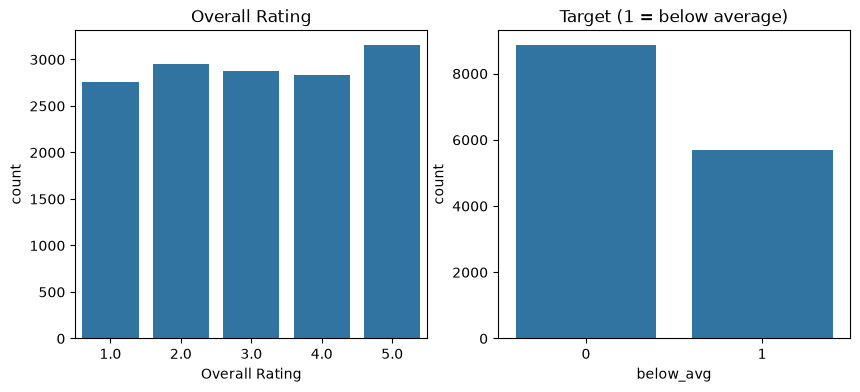

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x='Overall Rating', data=df, ax=ax[0])
ax[0].set_title('Overall Rating')
sns.countplot(x='below_avg', data=df, ax=ax[1])
ax[1].set_title('Target (1 = below average)')
plt.show()

Stars 1-5 are almost equal in size. The target is 39% vs 61%, so it is a bit imbalanced but not much.

### B.2 Columns I look at

Only operational columns (staffing, turnover, size, ownership).

In [16]:
num_cols = ['Number of Certified Beds', 'Average Number of Residents per Day',
            'Reported Nurse Aide Staffing Hours per Resident per Day',
            'Reported LPN Staffing Hours per Resident per Day',
            'Reported RN Staffing Hours per Resident per Day',
            'Reported Total Nurse Staffing Hours per Resident per Day',
            'Total number of nurse staff hours per resident per day on the weekend',
            'Reported Physical Therapist Staffing Hours per Resident Per Day',
            'Total nursing staff turnover', 'Registered Nurse turnover',
            'Number of administrators who have left the nursing home',
            'Nursing Case-Mix Index', 'Number of Facilities in Chain',
            'own_owners', 'own_org_owners']

cat_cols = ['State', 'Ownership Type', 'Provider Type', 'Urban', 'Provider Resides in Hospital',
            'Continuing Care Retirement Community', 'Provider Changed Ownership in Last 12 Months',
            'With a Resident and Family Council', 'Automatic Sprinkler Systems in All Required Areas']

In [17]:
df[num_cols + cat_cols].info()

<class 'pandas.DataFrame'>
Index: 14560 entries, 0 to 14683
Data columns (total 24 columns):
 #   Column                                                                 Non-Null Count  Dtype  
---  ------                                                                 --------------  -----  
 0   Number of Certified Beds                                               14558 non-null  float64
 1   Average Number of Residents per Day                                    14512 non-null  float64
 2   Reported Nurse Aide Staffing Hours per Resident per Day                14214 non-null  float64
 3   Reported LPN Staffing Hours per Resident per Day                       14214 non-null  float64
 4   Reported RN Staffing Hours per Resident per Day                        14214 non-null  float64
 5   Reported Total Nurse Staffing Hours per Resident per Day               14214 non-null  float64
 6   Total number of nurse staff hours per resident per day on the weekend  14214 non-null  float64
 7   Re

In [18]:
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Number of Certified Beds,14558.0,106.69,58.91,2.00,66.00,100.00,127.00,843.00
Average Number of Residents per Day,14512.0,85.77,50.03,1.00,52.50,78.40,107.30,731.80
Reported Nurse Aide Staffing Hours per Resident per Day,14214.0,2.35,0.56,0.00,2.00,2.25,2.59,12.80
Reported LPN Staffing Hours per Resident per Day,14214.0,0.86,0.35,0.00,0.65,0.85,1.05,5.68
Reported RN Staffing Hours per Resident per Day,14214.0,0.69,0.48,0.00,0.42,0.59,0.82,8.37
Reported Total Nurse Staffing Hours per Resident per Day,14214.0,3.90,0.91,0.00,3.37,3.71,4.22,15.44
Total number of nurse staff hours per resident per day on the weekend,14214.0,3.43,0.83,0.01,2.96,3.27,3.73,14.34
Reported Physical Therapist Staffing Hours per Resident Per Day,14213.0,0.07,0.09,0.00,0.02,0.05,0.09,2.42
Total nursing staff turnover,13509.0,45.25,14.33,0.00,35.20,44.60,54.40,100.00
Registered Nurse turnover,12734.0,42.37,20.67,0.00,27.30,40.60,56.50,100.00


Skewness, more than 1 means a long right tail.

In [19]:
df[num_cols].skew().round(2).sort_values()

Registered Nurse turnover                                                0.31
Total nursing staff turnover                                             0.35
Reported LPN Staffing Hours per Resident per Day                         1.47
Number of administrators who have left the nursing home                  1.61
Reported Nurse Aide Staffing Hours per Resident per Day                  1.81
Number of Facilities in Chain                                            2.30
Average Number of Residents per Day                                      2.46
Reported Total Nurse Staffing Hours per Resident per Day                 2.46
Total number of nurse staff hours per resident per day on the weekend    2.51
Nursing Case-Mix Index                                                   2.53
Number of Certified Beds                                                 2.60
own_org_owners                                                           3.02
Reported RN Staffing Hours per Resident per Day                 

Size and owner columns are very skewed. Max staffing of 15 hours per resident per day looks wrong (fixed in C).

### B.3 Missing values

In [20]:
missing = df[num_cols + cat_cols].isna().mean() * 100
missing[missing > 0].round(1).sort_values(ascending=False)

Number of Facilities in Chain                                            30.3
Registered Nurse turnover                                                12.5
Number of administrators who have left the nursing home                  11.0
Total nursing staff turnover                                              7.2
With a Resident and Family Council                                        5.1
Reported Nurse Aide Staffing Hours per Resident per Day                   2.4
Reported LPN Staffing Hours per Resident per Day                          2.4
Reported RN Staffing Hours per Resident per Day                           2.4
Reported Total Nurse Staffing Hours per Resident per Day                  2.4
Total number of nurse staff hours per resident per day on the weekend     2.4
Reported Physical Therapist Staffing Hours per Resident Per Day           2.4
Nursing Case-Mix Index                                                    2.4
Average Number of Residents per Day                             

- Chain size is missing when a home is not in a chain, so it means 0.
- Turnover (7-13%) and staffing (2.5%) are missing where CMS data failed checks.

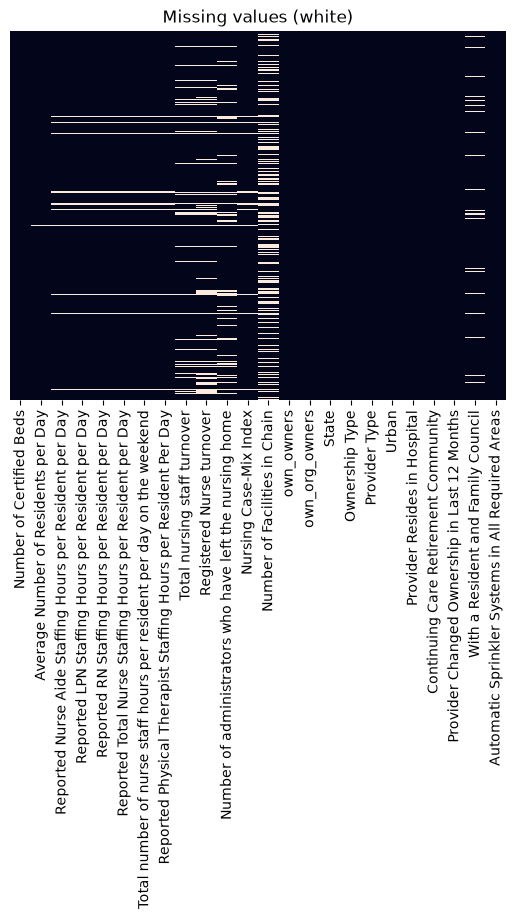

In [21]:
sns.heatmap(df[num_cols + cat_cols].isna(), cbar=False, yticklabels=False)
plt.title('Missing values (white)')
plt.show()

Staffing columns are missing for the same homes (one white band), so it is one problem, not many.

### B.4 Numeric features vs target

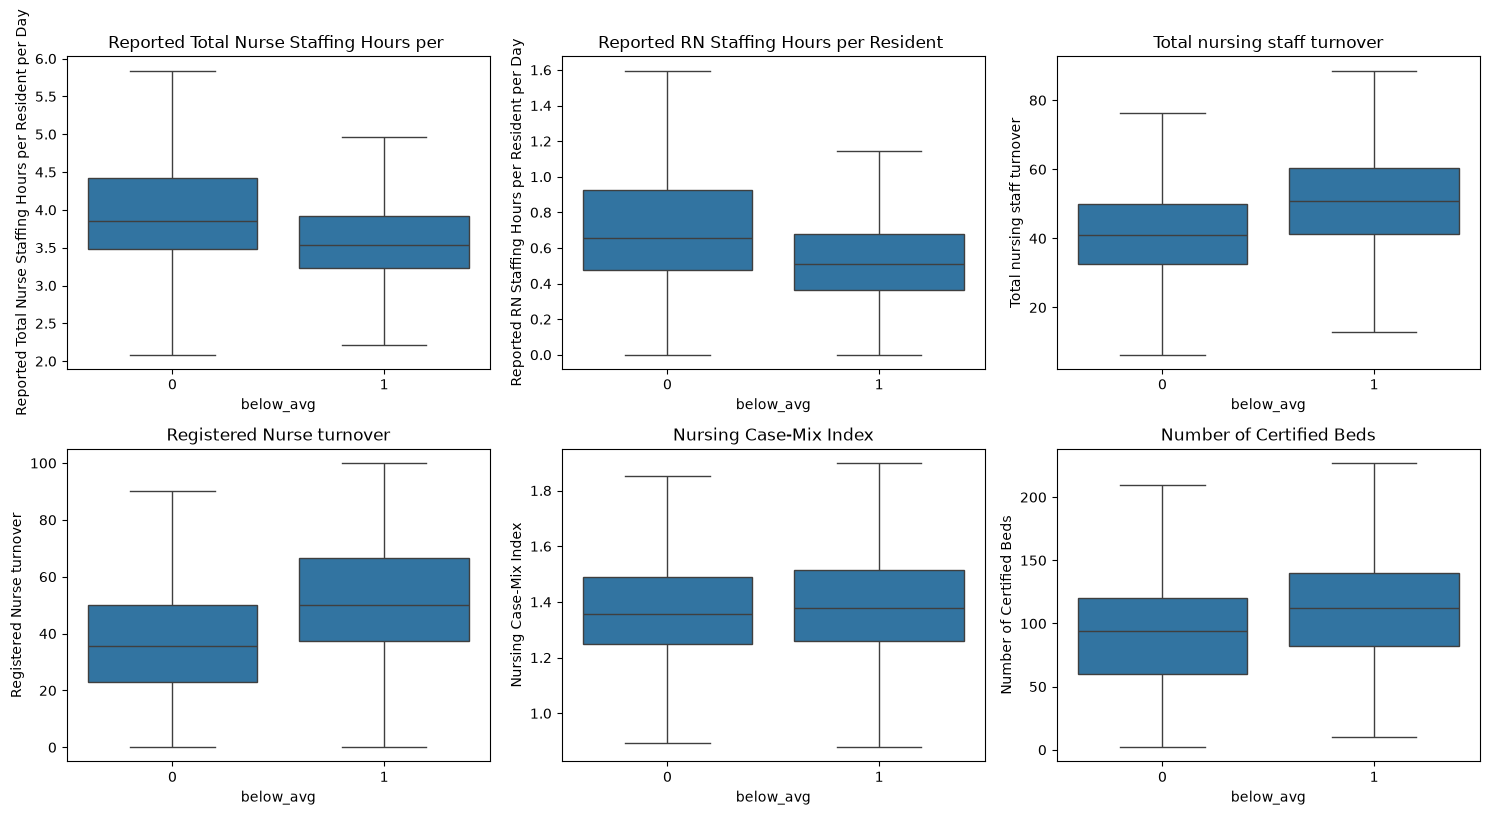

In [22]:
plot_cols = ['Reported Total Nurse Staffing Hours per Resident per Day',
             'Reported RN Staffing Hours per Resident per Day',
             'Total nursing staff turnover', 'Registered Nurse turnover',
             'Nursing Case-Mix Index', 'Number of Certified Beds']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), plot_cols):
    sns.boxplot(data=df, x='below_avg', y=col, ax=ax, showfliers=False)
    ax.set_title(col[:40])
plt.tight_layout()
plt.show()

Below-average homes have fewer staff hours and higher turnover (RN turnover 50% vs 36%).

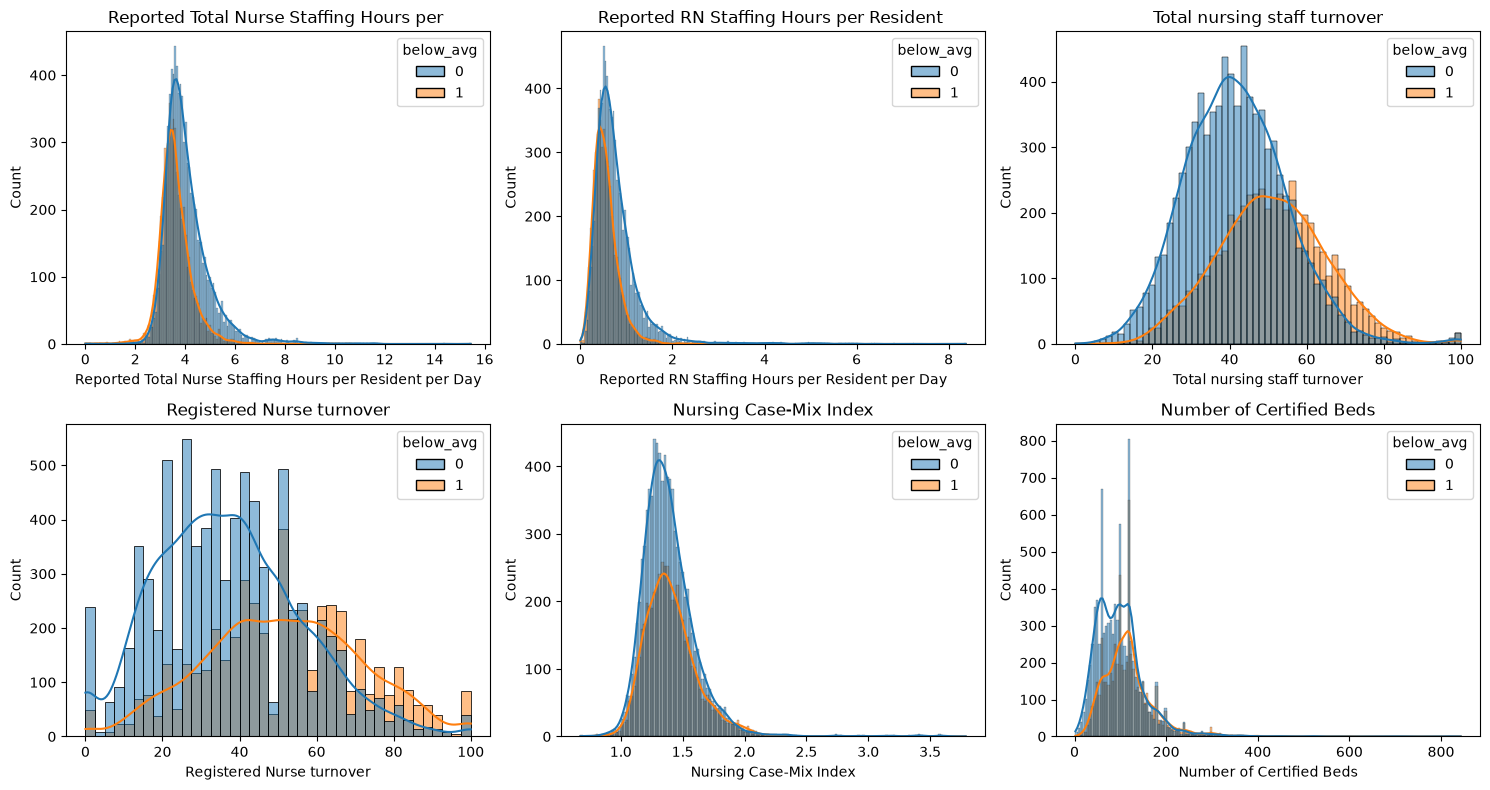

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), plot_cols):
    sns.histplot(data=df, x=col, hue='below_avg', kde=True, ax=ax)
    ax.set_title(col[:40])
plt.tight_layout()
plt.show()

### B.5 Categorical features vs target

Share of below-average homes in each group.

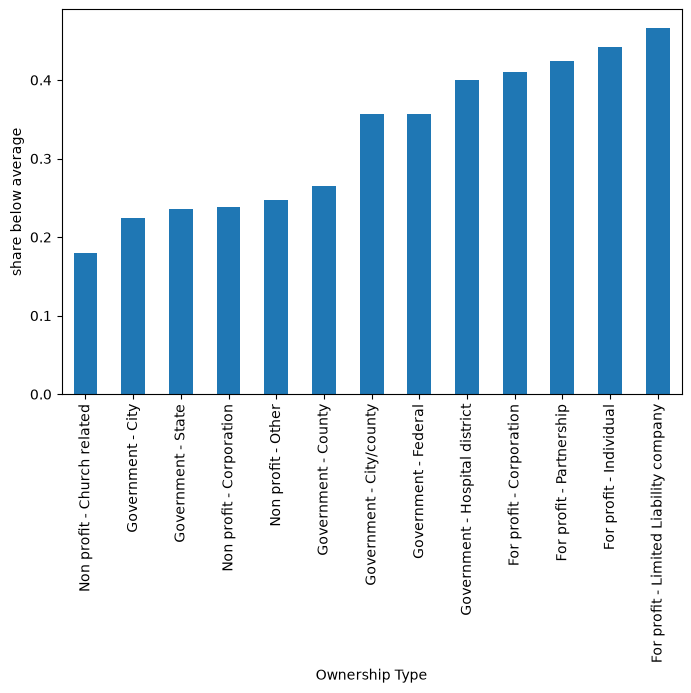

In [24]:
own_rate = df.groupby('Ownership Type')['below_avg'].mean().sort_values()

own_rate.plot(kind='bar', figsize=(8, 5))
plt.ylabel('share below average')
plt.show()

For-profit homes are below average more often (41-47%) than non-profit (18-25%). Overall it is 39%.

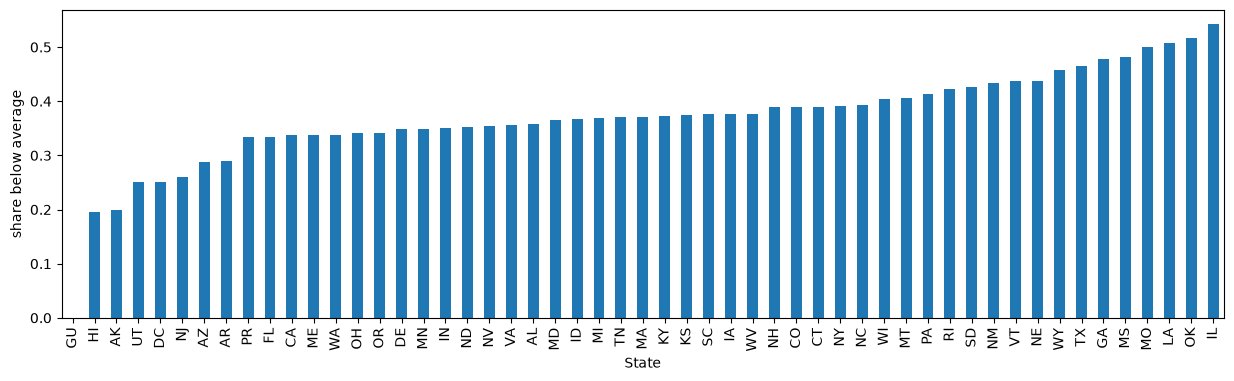

In [25]:
state_rate = df.groupby('State')['below_avg'].mean().sort_values()

state_rate.plot(kind='bar', figsize=(15, 4))
plt.ylabel('share below average')
plt.show()

State matters: from about 20% (Hawaii, Alaska) to 54% (Illinois). Each state does its own inspections.

In [26]:
for col in ['Urban', 'Provider Changed Ownership in Last 12 Months', 'With a Resident and Family Council',
            'Continuing Care Retirement Community', 'Provider Resides in Hospital']:
    print(df.groupby(col)['below_avg'].agg(['mean', 'count']).round(3), '\n')

        mean  count
Urban              
N      0.383   3975
Y      0.395  10585 

                                               mean  count
Provider Changed Ownership in Last 12 Months              
N                                             0.391  14501
Y                                             0.525     59 

                                     mean  count
With a Resident and Family Council              
Both                                0.374   1768
Resident                            0.402  12046 

                                       mean  count
Continuing Care Retirement Community              
N                                     0.414  13018
Y                                     0.204   1542 

                               mean  count
Provider Resides in Hospital              
N                             0.397  13955
Y                             0.264    605 



### B.6 Correlation matrix

Spearman, because many columns are skewed and it only uses the order of values.

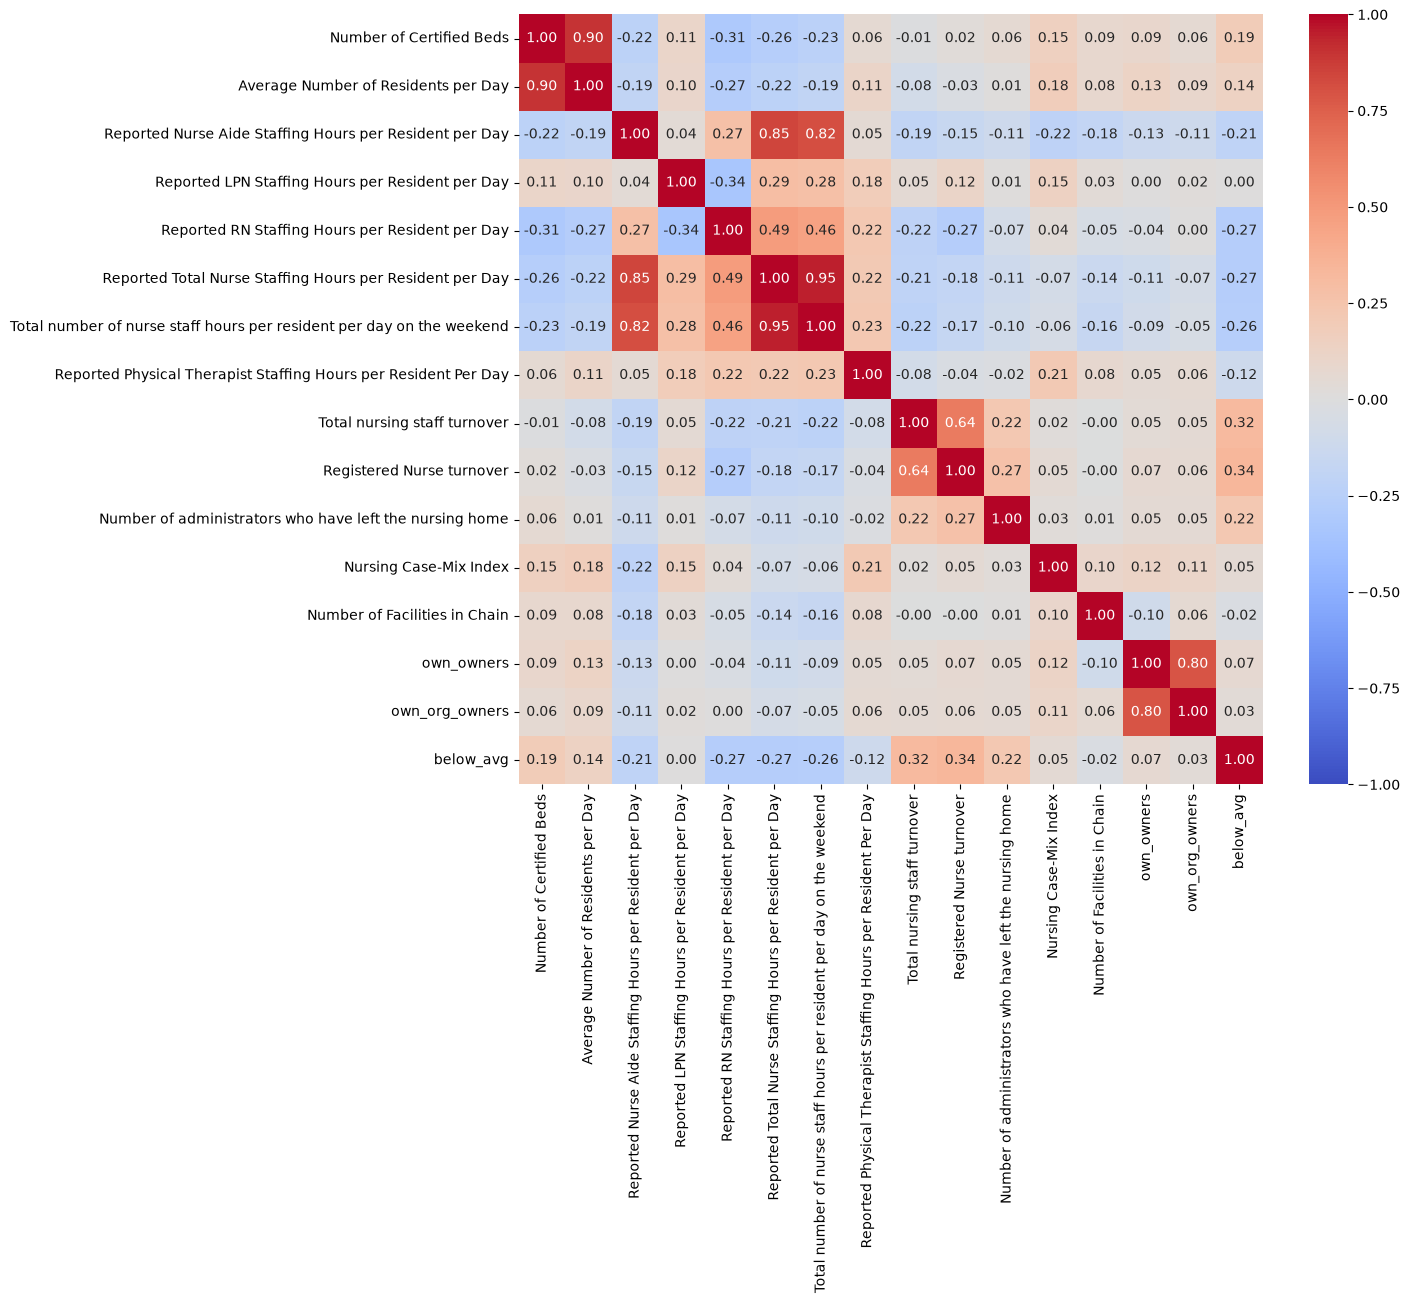

In [27]:
corr = df[num_cols + ['below_avg']].corr(method='spearman')

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

In [28]:
corr['below_avg'].drop('below_avg').sort_values()

Reported Total Nurse Staffing Hours per Resident per Day                -0.273239
Reported RN Staffing Hours per Resident per Day                         -0.265726
Total number of nurse staff hours per resident per day on the weekend   -0.260181
Reported Nurse Aide Staffing Hours per Resident per Day                 -0.208530
Reported Physical Therapist Staffing Hours per Resident Per Day         -0.115619
Number of Facilities in Chain                                           -0.024590
Reported LPN Staffing Hours per Resident per Day                         0.000722
own_org_owners                                                           0.033393
Nursing Case-Mix Index                                                   0.048472
own_owners                                                               0.066233
Average Number of Residents per Day                                      0.137407
Number of Certified Beds                                                 0.188219
Number of admini

- Turnover has the strongest link (+0.33), staffing hours are negative (-0.27). No single column decides the target.
- Beds and residents are 0.9+ correlated, so are weekday and weekend staffing.

### B.7 Leakage check

The same correlation for the rating columns and the inspection results.

In [29]:
leak_cols = ['Health Inspection Rating', 'Staffing Rating', 'QM Rating',
             'Total Weighted Health Survey Score', 'cit_total', 'cit_harm', 'pen_fines', 'pen_fines_usd']

df[leak_cols + ['below_avg']].corr(method='spearman')['below_avg'].round(2)

Health Inspection Rating             -0.78
Staffing Rating                      -0.38
QM Rating                            -0.35
Total Weighted Health Survey Score    0.68
cit_total                             0.53
cit_harm                              0.49
pen_fines                             0.45
pen_fines_usd                         0.46
below_avg                             1.00
Name: below_avg, dtype: float64

These are much stronger, because CMS builds the rating from them. Using them would be leakage, so I drop them in C.

## C. Data preparation

### C.1 Correcting error data

Residents per day should not be more than beds.

In [30]:
occupancy = df['Average Number of Residents per Day'] / df['Number of Certified Beds']
print((occupancy > 1).sum())
print(occupancy.dropna().sort_values().tail())

121
4447      2.490476
13704     2.716667
8592      4.616667
4998     11.200000
13610    13.291667
dtype: float64


Over 100% can happen (beds change during the year), but 2-13 times the beds is an error. Above 110% becomes NaN.

In [31]:
df['occupancy'] = occupancy
df.loc[df['occupancy'] > 1.1, 'occupancy'] = np.nan
print(df['occupancy'].isna().sum())

98


Staffing above 10 hours per resident per day is not realistic (median is 3.7, 24 hours is the whole day).

In [32]:
staff_cols = ['Reported Nurse Aide Staffing Hours per Resident per Day',
              'Reported LPN Staffing Hours per Resident per Day',
              'Reported RN Staffing Hours per Resident per Day',
              'Reported Total Nurse Staffing Hours per Resident per Day',
              'Total number of nurse staff hours per resident per day on the weekend']

too_high = df['Reported Total Nurse Staffing Hours per Resident per Day'] > 10
print(too_high.sum())
df.loc[too_high, staff_cols] = np.nan

29


Sprinkler column has "Data Not Available" as text, it is really missing.

In [33]:
sprinkler = 'Automatic Sprinkler Systems in All Required Areas'
print(df[sprinkler].value_counts())
df[sprinkler] = df[sprinkler].replace('Data Not Available', np.nan)

Automatic Sprinkler Systems in All Required Areas
Yes                   14483
Data Not Available       42
Partial                  35
Name: count, dtype: int64


### C.2 Feature engineering

In [34]:
# years since first certified (data is from Oct 2026)
first_year = df['Date First Approved to Provide Medicare and Medicaid Services'].apply(lambda d: int(d[:4]))
df['years_certified'] = 2026 - first_year

# not in a chain -> NaN, really 0
df['in_chain'] = df['Chain ID'].notna().astype(int)
df['chain_size'] = df['Number of Facilities in Chain'].fillna(0)

# weekend staffing compared to the whole week
df['weekend_ratio'] = (df['Total number of nurse staff hours per resident per day on the weekend']
                       / df['Reported Total Nurse Staffing Hours per Resident per Day'])

# RN share of all nurse hours
df['rn_share'] = (df['Reported RN Staffing Hours per Resident per Day']
                  / df['Reported Total Nurse Staffing Hours per Resident per Day'])

# share of owners that are companies
df['own_org_share'] = df['own_org_owners'] / df['own_owners']

In [35]:
new_features = ['occupancy', 'years_certified', 'in_chain', 'chain_size', 'weekend_ratio', 'rn_share', 'own_org_share']
df[new_features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
occupancy,14462.0,0.81,0.15,0.01,0.73,0.85,0.92,1.10
years_certified,14560.0,35.06,13.37,0.00,27.00,35.00,45.00,59.00
in_chain,14560.0,0.70,0.46,0.00,0.00,1.00,1.00,1.00
chain_size,14560.0,41.28,71.49,0.00,0.00,13.00,43.00,347.00
weekend_ratio,14185.0,0.88,0.06,0.38,0.85,0.88,0.91,3.51
rn_share,14185.0,0.17,0.08,0.00,0.12,0.16,0.21,1.00
own_org_share,10576.0,0.66,0.39,0.00,0.33,0.86,1.00,1.00


In [36]:
df[new_features + ['below_avg']].corr(method='spearman')['below_avg'].round(2)

occupancy         -0.12
years_certified    0.07
in_chain           0.07
chain_size         0.04
weekend_ratio      0.01
rn_share          -0.20
own_org_share     -0.07
below_avg          1.00
Name: below_avg, dtype: float64

- New features are weak on their own. Strongest: rn_share (-0.20) and occupancy (-0.12).
- Chain and older homes are slightly more often below average.
- Occupancy replaces residents, because residents and beds are 0.9+ correlated.

### C.3 Removing leakage and choosing features

I drop ratings, inspection scores, citations, fines, IDs, names and addresses. Only the columns below go into X.

In [37]:
num_features = ['Number of Certified Beds', 'occupancy',
                'Reported Nurse Aide Staffing Hours per Resident per Day',
                'Reported LPN Staffing Hours per Resident per Day',
                'Reported RN Staffing Hours per Resident per Day',
                'Reported Physical Therapist Staffing Hours per Resident Per Day',
                'weekend_ratio', 'rn_share',
                'Total nursing staff turnover', 'Registered Nurse turnover',
                'Number of administrators who have left the nursing home',
                'Nursing Case-Mix Index', 'years_certified', 'in_chain', 'chain_size',
                'own_owners', 'own_org_share']

cat_features = ['State', 'Ownership Type', 'Provider Type', 'Urban',
                'Provider Resides in Hospital', 'Continuing Care Retirement Community',
                'Provider Changed Ownership in Last 12 Months',
                'With a Resident and Family Council', sprinkler]

X = df[num_features + cat_features]
y = df['below_avg']
print(X.shape, y.shape)

(14560, 26) (14560,)


Total and weekend hours are left out: total = aide + LPN + RN, and weekend is now weekend_ratio.

### C.4 Missing values (what is left)

In [38]:
X.isna().sum()[X.isna().sum() > 0]

Number of Certified Beds                                              2
occupancy                                                            98
Reported Nurse Aide Staffing Hours per Resident per Day             375
Reported LPN Staffing Hours per Resident per Day                    375
Reported RN Staffing Hours per Resident per Day                     375
Reported Physical Therapist Staffing Hours per Resident Per Day     347
weekend_ratio                                                       375
rn_share                                                            375
Total nursing staff turnover                                       1051
Registered Nurse turnover                                          1826
Number of administrators who have left the nursing home            1597
Nursing Case-Mix Index                                              346
own_org_share                                                      3984
With a Resident and Family Council                              

- Numbers: median, because the columns are skewed.
- Categories: most frequent value.
- Done inside the pipeline, so it learns from training data only.

### C.5 Train/test split

80/20, stratified so both parts keep 39% below-average.

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(11648, 26) (2912, 26)
0.391 0.391


### C.6 Preprocessing pipeline

Impute missing values, scale numbers, one-hot encode categories.

In [40]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_features),
    ('cat', cat_pipe, cat_features)
])

In [41]:
# check on train only
X_train_prep = preprocessor.fit_transform(X_train)
print(X_train_prep.shape)

(11648, 98)


Scaling is needed for logistic regression and KNN (distances). Naive Bayes needs a dense table, so sparse_output=False.

## D. Models

Each model is a Pipeline (preprocessing + model), tuned with GridSearchCV and 5-fold stratified CV on the training set.

Always saying "not below average" is already 61% accurate, so I tune with ROC-AUC instead of accuracy.

In [42]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### D.1 Logistic Regression

C = regularisation strength (small C = simpler model).

In [43]:
lr_pipe = Pipeline([('prep', preprocessor), ('model', LogisticRegression(max_iter=2000))])
lr_params = {'model__C': [0.01, 0.1, 1, 10]}

lr_grid = GridSearchCV(lr_pipe, lr_params, cv=cv, scoring='roc_auc')
lr_grid.fit(X_train, y_train)
print(lr_grid.best_params_, round(lr_grid.best_score_, 3))

{'model__C': 0.1} 0.777


### D.2 KNN

k = number of neighbours, weights = whether closer neighbours count more.

In [44]:
knn_pipe = Pipeline([('prep', preprocessor), ('model', KNeighborsClassifier())])
knn_params = {'model__n_neighbors': [5, 15, 51, 101, 151, 201],
              'model__weights': ['uniform', 'distance']}

knn_grid = GridSearchCV(knn_pipe, knn_params, cv=cv, scoring='roc_auc', n_jobs=-1)
knn_grid.fit(X_train, y_train)
print(knn_grid.best_params_, round(knn_grid.best_score_, 3))

{'model__n_neighbors': 151, 'model__weights': 'distance'} 0.767


### D.3 Naive Bayes

GaussianNB has almost nothing to tune, var_smoothing adds a small value to the variances.

In [45]:
nb_pipe = Pipeline([('prep', preprocessor), ('model', GaussianNB())])
nb_params = {'model__var_smoothing': [1e-9, 1e-6, 1e-3, 1e-1]}

nb_grid = GridSearchCV(nb_pipe, nb_params, cv=cv, scoring='roc_auc')
nb_grid.fit(X_train, y_train)
print(nb_grid.best_params_, round(nb_grid.best_score_, 3))

{'model__var_smoothing': 0.1} 0.738


### D.4 Random Forest

max_depth = tree depth, min_samples_leaf = smallest leaf, max_features = columns per split.

In [46]:
rf_pipe = Pipeline([('prep', preprocessor), ('model', RandomForestClassifier(n_estimators=300, random_state=42))])
rf_params = {'model__max_depth': [10, 20, None],
             'model__min_samples_leaf': [1, 5, 10],
             'model__max_features': ['sqrt', 0.3]}

rf_grid = GridSearchCV(rf_pipe, rf_params, cv=cv, scoring='roc_auc', n_jobs=-1)
rf_grid.fit(X_train, y_train)
print(rf_grid.best_params_, round(rf_grid.best_score_, 3))

{'model__max_depth': 20, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1} 0.785


## E. Evaluation on the test set

The test set (2,912 homes) is used only here. Metrics: TPR, TNR, AUC, precision, F1, accuracy.

In [47]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

grids = {'Logistic Regression': lr_grid, 'KNN': knn_grid, 'Naive Bayes': nb_grid, 'Random Forest': rf_grid}

rows = []
for name, grid in grids.items():
    y_pred = grid.predict(X_test)
    y_prob = grid.predict_proba(X_test)[:, 1]
    report = classification_report(y_test, y_pred, output_dict=True)
    rows.append({'model': name,
                 'CV AUC': grid.best_score_,
                 'test AUC': roc_auc_score(y_test, y_prob),
                 'TPR (recall)': report['1']['recall'],
                 'TNR': report['0']['recall'],
                 'precision': report['1']['precision'],
                 'F1': report['1']['f1-score'],
                 'accuracy': report['accuracy']})

results = pd.DataFrame(rows).set_index('model').round(3)
results

,CV AUC,test AUC,TPR (recall),TNR,precision,F1,accuracy
model,,,,,,,
Logistic Regression,0.777,0.770,0.528,0.822,0.656,0.585,0.707
KNN,0.767,0.773,0.417,0.886,0.702,0.523,0.702
Naive Bayes,0.738,0.734,0.813,0.491,0.507,0.624,0.617
Random Forest,0.785,0.784,0.522,0.843,0.682,0.591,0.717


- Random Forest is best (AUC 0.78). CV and test scores match, so no overfitting.
- It finds half of the below-average homes (TPR 0.52) and rarely flags a good one (TNR 0.84).
- Naive Bayes finds more (81%) but flags half of the good homes.

### E.1 Final model

Random Forest has the best CV AUC (training data), so the test set does not choose the model.

              precision    recall  f1-score   support

           0       0.73      0.84      0.78      1772
           1       0.68      0.52      0.59      1140

    accuracy                           0.72      2912
   macro avg       0.71      0.68      0.69      2912
weighted avg       0.71      0.72      0.71      2912



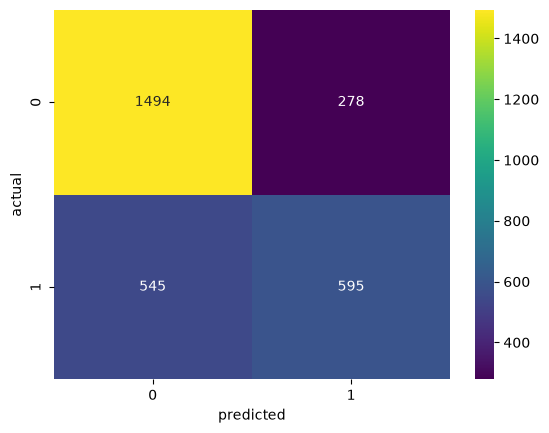

In [48]:
final_model = rf_grid.best_estimator_

y_pred = final_model.predict(X_test)
print(classification_report(y_test, y_pred))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='viridis')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.show()

### E.2 Saving the final model

For the Streamlit app.

In [49]:
import joblib

joblib.dump(final_model, '../models/final_model.joblib')
results.to_csv('../models/test_results.csv')